# Week 3, day 5 on a Mac: token predictions and a meeting-minutes creator

The course version uses `gpt-4.1-mini` for the token visualizer and a Colab T4 for the meeting
minutes. Here both run locally:

- **Token visualizer** – Ollama's OpenAI-compatible endpoint also returns `logprobs`, so the
  course's `TokenPredictor` works unchanged once it points at Ollama.
- **Meeting minutes** – macOS `say` records a short Spanish-class meeting, Whisper (via
  transformers, on `mps`) transcribes it, and a local Ollama model writes the minutes.

Start Ollama first (`ollama serve`) with `llama3.2` pulled.

## Something cool – watching model inference token by token

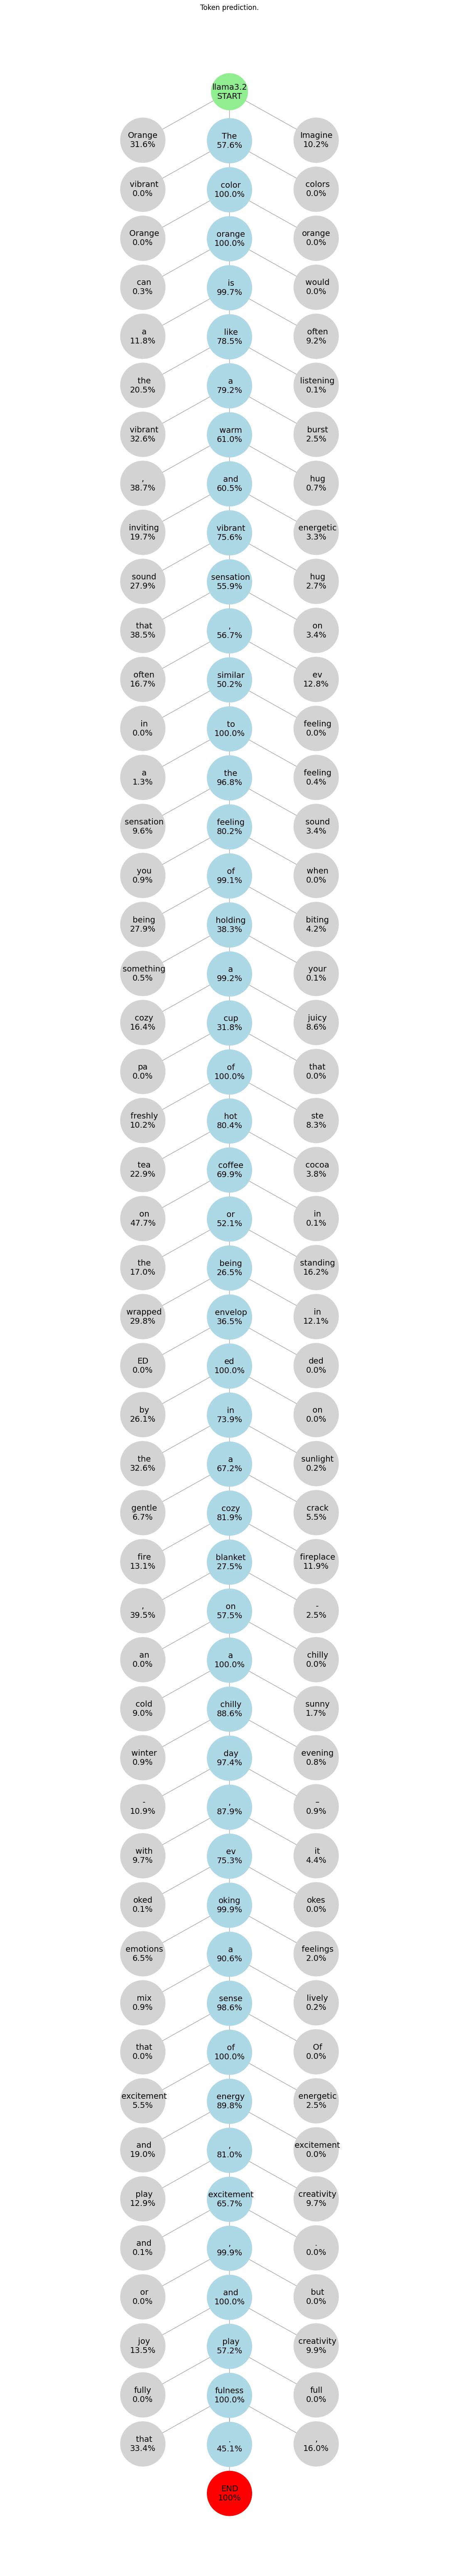

In [1]:
from openai import OpenAI
from visualizer import TokenPredictor, create_token_graph, visualize_predictions

OLLAMA_URL = "http://localhost:11434/v1"
LOCAL_MODEL = "llama3.2"

class LocalTokenPredictor(TokenPredictor):
    """The course's TokenPredictor, talking to Ollama instead of OpenAI."""
    def __init__(self, model_name):
        self.client = OpenAI(base_url=OLLAMA_URL, api_key="ollama")
        self.messages, self.predictions, self.model_name = [], [], model_name

message = "In one sentence, describe the color orange to someone who has never been able to see"
predictor = LocalTokenPredictor(LOCAL_MODEL)
predictions = predictor.predict_tokens(message)
G = create_token_graph(LOCAL_MODEL, predictions)
plt = visualize_predictions(G)
plt.show()

## Meeting minutes creator

First, a short recording. Swap `AUDIO_FILE` for your own 16 kHz mono WAV to use a real meeting.

In [2]:
import subprocess
from pathlib import Path

AUDIO_FILE = Path("meeting.wav")
SCRIPT = (
    "Good morning everyone, this is the weekly planning meeting for the Spanish course. "
    "Maria reported that twelve students finished the A2 unit on the past tense. "
    "Tom said the flashcard decks need more food vocabulary, and he will add fifty new cards by Friday. "
    "We agreed to move the speaking practice session from Tuesday to Thursday afternoon. "
    "Maria will email the students about the change today. "
    "Next meeting is Monday at ten."
)
# 16 kHz little-endian 16-bit WAV, which Whisper can read without ffmpeg
subprocess.run(["say", "-o", str(AUDIO_FILE), "--data-format=LEI16@16000", SCRIPT], check=True)
AUDIO_FILE.stat().st_size

848726

In [3]:
import torch
from scipy.io import wavfile
from transformers import pipeline

device = "mps" if torch.backends.mps.is_available() else "cpu"
transcriber = pipeline("automatic-speech-recognition", model="openai/whisper-base", device=device)

rate, samples = wavfile.read(AUDIO_FILE)
audio = samples.astype("float32") / 32768.0  # int16 -> [-1, 1]
transcription = transcriber({"raw": audio, "sampling_rate": rate}, return_timestamps=True)["text"]
print(transcription)

 Good morning, everyone. This is the weekly planning meeting for the Spanish course. Maria reported that 12 students finished the A2 unit on the past tense. Tom said the flashcard decks need more food vocabulary, and he will add 50 new cards by Friday. We agreed to move the speaking practice session from Tuesday to Thursday afternoon. Maria will email the students about the change today. Next meeting is Monday at 10.


In [4]:
from IPython.display import Markdown, display

client = OpenAI(base_url=OLLAMA_URL, api_key="ollama")

system_message = """You produce minutes of meetings from transcripts, with a summary, key discussion points,
takeaways and action items with owners, in markdown format without code blocks."""
user_prompt = f"""Below is a transcript of a Spanish-course planning meeting.
Write minutes in markdown: a summary with date and attendees if mentioned, discussion points,
takeaways, and action items with owners.

{transcription}"""

stream = client.chat.completions.create(
    model=LOCAL_MODEL,
    messages=[{"role": "system", "content": system_message}, {"role": "user", "content": user_prompt}],
    stream=True,
)
minutes = "".join(chunk.choices[0].delta.content or "" for chunk in stream)
display(Markdown(minutes))

# Meeting Minutes
# ===============

## Summary
----------------

*Date: [Insert Date]*
*Attendees: [Insert Attendees]*

The primary focus of the meeting was to finalize the Spanish course planning for the upcoming week. Key discussions centered on improving the flashcard decks, adjusting the speaking practice schedule, and scheduling the next meeting.

## Discussion Points
-------------------

* The use of flashcard decks will be enhanced to include more food vocabulary.
* Tom will add 50 new cards to the decks by Friday.

## Takeaways
-------------

* The speaking practice session will be moved from Tuesday to Thursday afternoon.

## Action Items
----------------

* Maria will send an email to the students about the change in speaking practice schedule today.
* Tom: Add 50 new food vocabulary flashcards to the decks by Friday.

Note: Please let me know if you would like to add the date and attendees to the minutes?